# 02 · Cleaning, validation design & the `quote_signal` experiment
**Goal:** build everything we need to trust a model score *before* we build the model.
1. Reusable **cleaning** functions (rules fitted on train only).
2. A **validation scheme** that mimics the hidden Nov–Dec test. time-based train/test split , forward validation test
3. **Metrics**: we will try all metrics for evaluation.
4. **Baselines** — the bar any ML model must beat.
5. Settle the **`quote_signal`** question with evidence.

> Rule of this notebook: *every decision is justified by a number i compute here.*

In [31]:
import os, sys, glob, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False, 'axes.spines.right': False})

here = Path.cwd()
PROJECT_DIR = here.parent if here.name == 'notebooks' else here
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

def resolve_data_dir() -> Path:
    if 'DATA_DIR' in os.environ and Path(os.environ['DATA_DIR']).is_dir():
        return Path(os.environ['DATA_DIR'])
    for candidate in [PROJECT_DIR / 'data', here / 'data', Path.home() / 'Downloads']:
        if candidate.is_dir() and any(candidate.glob('*train*.csv')):
            return candidate
    return PROJECT_DIR / 'data'

DATA_DIR = resolve_data_dir()

def find(stem):
    candidates = [DATA_DIR, PROJECT_DIR / 'data', Path('data')]
    names = [stem, stem.replace('_', '-')]
    for d in candidates:
        if not d.is_dir():
            continue
        for n in names:
            if (d / f'{n}.csv').is_file():
                return str(d / f'{n}.csv')
        for n in names:
            hits = sorted(glob.glob(str(d / f'{n} (*).csv')))
            if hits:
                return hits[0]
    raise FileNotFoundError(f'Could not find {stem}.csv in {DATA_DIR}.')

tr_raw  = pd.read_csv(find('train_test'), parse_dates=['date'])
va_raw  = pd.read_csv(find('validation'), parse_dates=['date'])
dec_raw = pd.read_csv(find('december_chart_inputs'), parse_dates=['date'])
print('train_test:', tr_raw.shape, '| validation:', va_raw.shape, '| december:', dec_raw.shape)


(48000, 14) (12000, 13) (31, 7)


## 1 · Cleaning
**Principles**
- **Fit on train, apply everywhere.** Medians used for imputation come from training data only, then are applied identically to validation and December. (Otherwise validation information leaks into training.)
- **Never drop rows we must predict.** All 12,000 validation rows need a prediction, so for features we *repair*, we don't *delete*.
- **Label noise is different:** bad *labels* exist only in train, so we may drop those rows from training (never from evaluation of the real hidden set — we can't see its labels anyway).

| Problem | Fix | Why |
|---|---|---|
| negative `weight` | `abs()` | sign error: magnitudes look normal and rates match positive-weight loads |
| missing `weight` | median weight of that equipment type (train) | tiny share (0.6%), weak feature |
| missing `market_index` | median of that **day's** other loads | `market_index` is one number per day + tiny noise |
| corrupted `posted_rate` | flag via ratio-to-expected, drop from training only | random noise, can't be learned |

In [16]:
def fit_cleaner(train):
    """Learn imputation values from TRAIN only."""
    return {"weight_median": train.assign(w=train.weight.abs()).groupby("equipment").w.median().to_dict()}

def clean_features(df, params):
    d = df.copy()
    d["weight"] = d.weight.abs()                                            # fix sign errors
    d["weight"] = d.weight.fillna(d.equipment.map(params["weight_median"])) # impute
    d["mi_day"] = d.groupby("date").market_index.transform("median")        # robust daily market level
    d["market_index"] = d.market_index.fillna(d["mi_day"])
    d["t"] = (d.date - pd.Timestamp("2025-01-01")).dt.days                  # days since start (for trend studies)
    return d

params = fit_cleaner(tr_raw)
tr, va = clean_features(tr_raw, params), clean_features(va_raw, params)
print("weight medians:", {k: round(v) for k, v in params["weight_median"].items()})
print("Remaining NaNs  train:", int(tr[["weight","market_index","mi_day"]].isna().sum().sum()), "| val:", int(va[["weight","market_index","mi_day"]].isna().sum().sum()))

# December rows have no market_index -> take each day's value from validation.csv 
va_daily_mi = va.groupby("date").mi_day.first()
dec = dec_raw.copy(); dec["mi_day"] = dec.date.map(va_daily_mi)
print("December days with a market_index from validation.csv:", int(dec.mi_day.notna().sum()), "/ 31")

weight medians: {'Dry Van': 31444, 'Flatbed': 31532, 'Reefer': 31577}
Remaining NaNs  train: 0 | val: 0
December days with a market_index from validation.csv: 31 / 31


### 1b · Corrupted labels

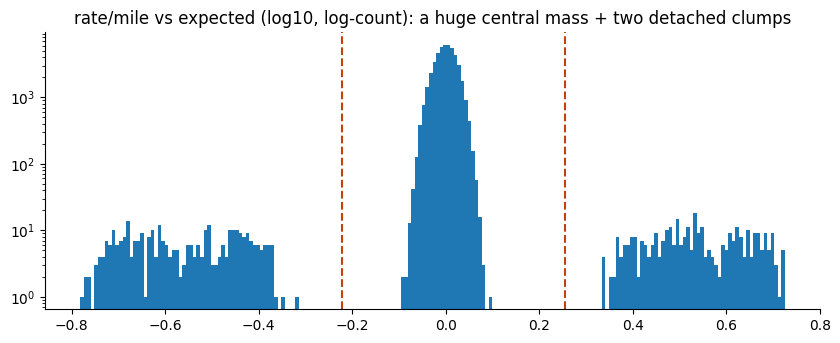

flagged: 677 rows = 1.41%   (too low: 337, too high: 340)
Rows with ratio between 0.6-0.8 or 1.4-1.8 (the grey zone): 0
noise share by month: {1: 0.0165, 2: 0.0131, 3: 0.0141, 4: 0.0137, 5: 0.0126, 6: 0.0132, 7: 0.0132, 8: 0.0143, 9: 0.0137, 10: 0.0165}


In [17]:
tr["rpm"] = tr.posted_rate / tr.distance
DIST_BINS = [0, 100, 150, 200, 300, 400, 500, 650, 800, 1000, 1200, 1500, 2000, 2500, 4000]
tr["dbin"] = pd.cut(tr.distance, DIST_BINS)
ref = tr.groupby(["equipment", "dbin"], observed=True).rpm.transform("median")   # 'expected' rate/mile for that kind of load
tr["ratio"] = tr.rpm / ref

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(np.log10(tr.ratio), bins=200); ax.set_yscale("log")
for x in (0.6, 1.8): ax.axvline(np.log10(x), color="#C2410C", ls="--")
ax.set_title("rate/mile vs expected (log10, log-count): a huge central mass + two detached clumps"); plt.show()

LOW, HIGH = 0.6, 1.8
tr["noise"] = (tr.ratio < LOW) | (tr.ratio > HIGH)
print(f"flagged: {tr.noise.sum()} rows = {tr.noise.mean():.2%}   (too low: {(tr.ratio<LOW).sum()}, too high: {(tr.ratio>HIGH).sum()})")
print("Rows with ratio between 0.6-0.8 or 1.4-1.8 (the grey zone):", int(tr.ratio.between(0.6,0.8).sum() + tr.ratio.between(1.4,1.8).sum()))
print("noise share by month:", tr.groupby(tr.date.dt.month).noise.mean().round(4).to_dict())

The corrupted rates sit in two clumps far from the main mass (almost nothing in the grey zone), so the thresholds are not delicate. The share is ~1.4% in every month → random noise.

**Why it matters for the score:** RMSE is dominated by these rows. A *perfect* model would still score badly on RMSE if the hidden labels contain them. That's why we'll report metrics on **all rows** *and* **clean rows**, and compare models on the clean rows (the part we can influence).

## 2 · Metrics
The assessment doesn't say how Spotter scores. We compute four, each tells a different story:

| Metric | Meaning | Sensitive to |
|---|---|---|
| **MAE** ($) | average dollar miss | robust, easy to explain |
| **RMSE** ($) | penalises big misses | outliers / corrupted labels |
| **MAPE** (%) | average % miss | cheap short loads |
| **WAPE** (%) | total $ error / total $ | big-ticket long loads |

In [18]:
def metrics(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float); e = p - y
    return {"MAE": np.mean(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)), "MAPE%": np.mean(np.abs(e)/y)*100, "WAPE%": np.abs(e).sum()/y.sum()*100}

def evaluate(test, pred):
    ok = ~test.noise.values
    return {**{f"{k}": v for k, v in metrics(test.posted_rate[ok], pred[ok]).items()},
            "RMSE_all": metrics(test.posted_rate, pred)["RMSE"], "MAE_all": metrics(test.posted_rate, pred)["MAE"]}

## 3 · Validation design
**The hidden test is the future (Nov–Dec), 2 months ahead of the last training day.** So our validation must also predict the future, 2 months ahead:

| Fold | Train | Test | Role |
|---|---|---|---|
| V1 | Jan–Jun | Jul–Aug | early, little history |
| V2 | Jan–Jul | Aug–Sep | |
| **V3** | Jan–Aug | **Sep–Oct** | **closest to the real situation** (most history) |

We average V1–V3, but weigh V3 most when in doubt. We never shuffle rows across time.

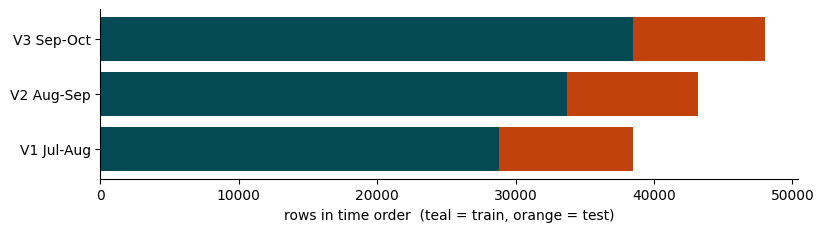

{'V1 Jul-Aug': (28806, 9671), 'V2 Aug-Sep': (33718, 9429), 'V3 Sep-Oct': (38477, 9523)}


In [19]:
mo = tr.date.dt.month
FOLDS = {"V1 Jul-Aug": (mo <= 6, mo.isin([7, 8])),
         "V2 Aug-Sep": (mo <= 7, mo.isin([8, 9])),
         "V3 Sep-Oct": (mo <= 8, mo.isin([9, 10]))}
fig, ax = plt.subplots(figsize=(9, 2.2))
for i, (n, (a, b)) in enumerate(FOLDS.items()):
    ax.barh(i, a.sum(), color="#064A56"); ax.barh(i, b.sum(), left=a.sum(), color="#C2410C")
ax.set_yticks(range(3)); ax.set_yticklabels(FOLDS.keys()); ax.set_xlabel("rows in time order  (teal = train, orange = test)"); plt.show()
print({n: (int(a.sum()), int(b.sum())) for n, (a, b) in FOLDS.items()})

### 3b · Baselines — the bar to beat

In [21]:
def baseline_global(trn, tst):                       # one rate/mile for everyone
    return np.full(len(tst), trn[~trn.noise].rpm.median()) * tst.distance.values
def baseline_group(trn, tst):                        # rate/mile by equipment x distance band
    med = trn[~trn.noise].groupby(["equipment", "dbin"], observed=True).rpm.median()
    return tst.set_index(["equipment", "dbin"]).index.map(med).values.astype(float) * tst.distance.values

rows = []
for fn, name in [(baseline_global, "global $/mile"), (baseline_group, "equipment x distance $/mile")]:
    for f, (a, b) in FOLDS.items():
        rows.append({"model": name, "fold": f, **evaluate(tr[b], fn(tr[a], tr[b]))})
base = pd.DataFrame(rows); base.round(2)

,model,fold,MAE,RMSE,MAPE%,WAPE%,RMSE_all,MAE_all
0,global $/mile,V1 Jul-Aug,199.15,289.88,9.03,8.49,674.72,249.02
1,global $/mile,V2 Aug-Sep,213.49,315.03,9.35,9.11,674.12,261.26
2,global $/mile,V3 Sep-Oct,203.69,295.92,9.27,8.63,684.25,256.95
3,equipment x distance $/mile,V1 Jul-Aug,82.54,115.01,3.65,3.52,629.91,134.09
4,equipment x distance $/mile,V2 Aug-Sep,77.57,107.38,3.50,3.31,620.07,127.77
5,equipment x distance $/mile,V3 Sep-Oct,78.22,106.96,3.51,3.31,638.25,133.92


A plain lookup table (equipment × distance band) already gets WAPE ≈ 3.3–3.5% on clean rows. Our model has to beat *this*, not zero.

In [22]:
# A quick, untuned GBM used ONLY for the experiments below - we will train properly later.
EQ = {"Dry Van": 0, "Flatbed": 1, "Reefer": 2}
def feats(d, qs=False):
    X = pd.DataFrame({"ldist": np.log(d.distance), "weight": d.weight, "equip": d.equipment.map(EQ),
                      "plat": d.pickup_lat, "plon": d.pickup_lon, "dlat": d.delivery_lat, "dlon": d.delivery_lon,
                      "mi": d.mi_day})
    if qs: X["qs"] = d.quote_signal.values
    return X
P = dict(n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=40, subsample=0.8,
         subsample_freq=1, colsample_bytree=0.9, verbose=-1, n_jobs=4)
def gbm_predict(trn, tst, qs=False):
    c = trn[~trn.noise]
    m = lgb.LGBMRegressor(**P).fit(feats(c, qs), np.log(c.rpm))          # model log(rate per mile)
    return np.exp(m.predict(feats(tst, qs))) * tst.distance.values

## 4 · Why we refuse a random split
Same model, same data. Only the *validation method* changes.

In [24]:
from sklearn.model_selection import KFold
ok = ~tr.noise.values
pr = np.zeros(len(tr))
for a, b in KFold(5, shuffle=True, random_state=0).split(tr):
    pr[b] = gbm_predict(tr.iloc[a], tr.iloc[b])
rand = metrics(tr.posted_rate[ok], pr[ok])
fwd = pd.DataFrame([evaluate(tr[b], gbm_predict(tr[a], tr[b])) for a, b in FOLDS.values()], index=FOLDS.keys())
print("RANDOM 5-fold   MAE = %.1f   WAPE = %.2f%%" % (rand["MAE"], rand["WAPE%"]))
print("FORWARD (mean)  MAE = %.1f   WAPE = %.2f%%" % (fwd["MAE"].mean(), fwd["WAPE%"].mean()))
fwd.round(2)

RANDOM 5-fold   MAE = 43.4   WAPE = 1.85%
FORWARD (mean)  MAE = 91.4   WAPE = 3.89%


,MAE,RMSE,MAPE%,WAPE%,RMSE_all,MAE_all
V1 Jul-Aug,57.66,80.13,2.43,2.46,624.69,109.53
V2 Aug-Sep,100.67,138.19,4.21,4.30,631.44,150.57
V3 Sep-Oct,115.80,149.70,4.83,4.91,652.36,170.79


The random split reports roughly **half** the real forward error. Why? Neighbouring days share the same daily market level (`market_index` is nearly a *date fingerprint*). In a random split a test row's day is also in training, so the tree has already seen that day's market conditions. In the real future, that doesn't exist. **A random split would have told us a comforting lie.**

**A second, uncomfortable finding:** on the honest forward folds this untuned GBM (WAPE ≈ 3.9%) is *worse* than the simple equipment × distance lookup (≈ 3.4%). Throwing a flexible model at the data is not enough; the way it handles the daily market level is hurting it. Fixing that is the main job of notebook 03.

## 5 · The `quote_signal` experiment
Hypothesis from EDA: `quote_signal` is real but its *sign* depends on a hidden regime. We (1) measure the slope per month, (2) see whether the hidden Nov–Dec period looks like any known regime, (3) run an ablation.

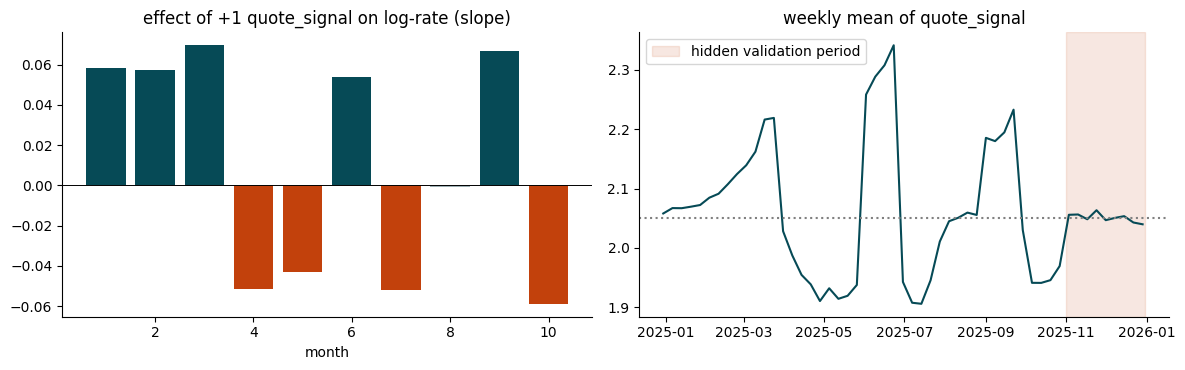

slope by month: {1: 0.058, 2: 0.057, 3: 0.07, 4: -0.051, 5: -0.043, 6: 0.054, 7: -0.052, 8: -0.001, 9: 0.067, 10: -0.059}

Validation (Nov-Dec) quote_signal: weekly mean range 2.043 - 2.063 | weekly std ~ 0.22
August (neutral month)           : weekly mean range 2.045 - 2.059 | weekly std ~ 0.223


In [25]:
c = tr[~tr.noise].copy()
c["res"] = np.log(c.rpm) - np.log(c.rpm).groupby([c.equipment, pd.cut(c.distance, DIST_BINS)], observed=True).transform("mean")
slope = c.groupby(c.date.dt.month).apply(lambda g: np.polyfit(g.quote_signal, g.res, 1)[0], include_groups=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(slope.index, slope.values, color=np.where(slope > 0.02, "#064A56", np.where(slope < -0.02, "#C2410C", "#9DAFB3")))
ax[0].axhline(0, color="k", lw=.7); ax[0].set_xlabel("month"); ax[0].set_title("effect of +1 quote_signal on log-rate (slope)")

allq = pd.concat([tr[["date", "quote_signal"]], va[["date", "quote_signal"]]])
wk = allq.groupby(allq.date.dt.to_period("W")).quote_signal.agg(["mean", "std"]); x = wk.index.to_timestamp()
ax[1].plot(x, wk["mean"], color="#064A56"); ax[1].axhline(2.05, color="grey", ls=":")
ax[1].axvspan(pd.Timestamp("2025-11-01"), pd.Timestamp("2025-12-31"), color="#C2410C", alpha=.12, label="hidden validation period")
ax[1].set_title("weekly mean of quote_signal"); ax[1].legend(); plt.tight_layout(); plt.show()
print("slope by month:", slope.round(3).to_dict())
st = wk.index.start_time
wv = wk[(st >= "2025-11-03") & (st <= "2025-12-22")]      # full weeks inside the hidden period
wa = wk[(st >= "2025-08-04") & (st <= "2025-08-25")]      # full August weeks
print("\nValidation (Nov-Dec) quote_signal: weekly mean range", wv["mean"].min().round(3), "-", wv["mean"].max().round(3), "| weekly std ~", wv["std"].mean().round(3))
print("August (neutral month)           : weekly mean range", wa["mean"].min().round(3), "-", wa["mean"].max().round(3), "| weekly std ~", wa["std"].mean().round(3))

**What we see**
- The slope is clearly positive (Jan–Mar, Jun, Sep), clearly negative (Apr–May, Jul, Oct) and ≈0 in **August**. The regimes line up with the *level* of `quote_signal` itself: ≈2.2 when positive, ≈1.93 when negative, ≈2.05 when neutral.
- The hidden Nov–Dec `quote_signal` has weekly mean ≈ 2.05 and std ≈ 0.22 in *every* week. That is the **August (neutral) fingerprint**. Nothing in the unlabeled test data suggests a regime with a usable slope.

Now the ablation: does including `quote_signal` help, specifically in a neutral period?

In [27]:
folds_q = {**FOLDS, "Aug only (neutral)": (mo <= 7, mo == 8)}
res = []
for f, (a, b) in folds_q.items():
    for q in (False, True):
        res.append({"fold": f, "uses quote_signal": q, **evaluate(tr[b], gbm_predict(tr[a], tr[b], qs=q))})
abl = pd.DataFrame(res)
abl.pivot(index="fold", columns="uses quote_signal", values="MAE").round(1)

uses quote_signal,False,True
fold,,
Aug only (neutral),64.2,93.0
V1 Jul-Aug,57.7,74.1
V2 Aug-Sep,100.7,72.9
V3 Sep-Oct,115.8,81.5


| Fold | what it tells us |
|---|---|
| V3 Sep–Oct, V2 Aug–Sep | `quote_signal` helps — but those months are in a **non-neutral** regime, *unlike* the hidden period |
| **Aug only** | the only neutral test we have: adding `quote_signal` makes it **much worse** (≈ +45% MAE: 64 → 93) |
| V1 Jul–Aug | worse as well |

**Decision.** The hidden period looks neutral, and in neutral periods `quote_signal` is harmful. Because we can't observe labels there, the conservative, defensible choice is **exclude `quote_signal` from the production model**. (next we'll also test a *regime-aware* variant as a documented ablation, and in the report we'll say exactly this: "gain in non-neutral months, loss in the neutral month that matches validation".)

> Honesty note: this is a judgment under uncertainty, not a proof. If Nov–Dec secretly had a regime, we'd lose some accuracy. We accept that because the downside of being wrong the *other* way (wrong sign) is larger than the upside.

## 6 · The market component (preview for feature engineering)
At the **daily** level, how much of the day's rate level can `market_index` and a time drift explain?

R2  mi only           : 0.487
R2  time only         : 0.268
R2  mi + time         : 0.846 | log-rate per +1.0 mi: 0.143 | per day: 0.00021


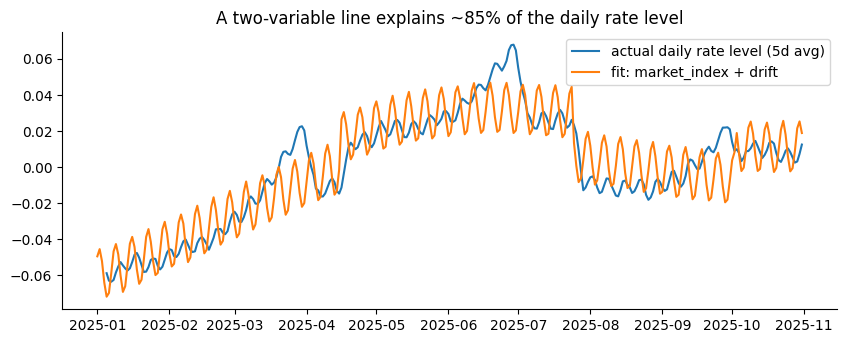

In [28]:
dd = c.groupby("date").agg(res=("res", "mean"), mi=("mi_day", "first"), t=("t", "first"))
def r2(X, y):
    b = np.linalg.lstsq(X, y, rcond=None)[0]; return 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum(), b
one = np.ones(len(dd))
print("R2  mi only           :", round(r2(np.c_[one, dd.mi], dd.res.values)[0], 3))
print("R2  time only         :", round(r2(np.c_[one, dd.t], dd.res.values)[0], 3))
r, b = r2(np.c_[one, dd.mi, dd.t], dd.res.values)
print("R2  mi + time         :", round(r, 3), "| log-rate per +1.0 mi:", round(b[1], 3), "| per day:", round(b[2], 5))
fig, ax = plt.subplots(figsize=(10, 3.6)); ax.plot(dd.index, dd.res.rolling(5).mean(), label="actual daily rate level (5d avg)")
ax.plot(dd.index, np.c_[one, dd.mi, dd.t] @ b, label="fit: market_index + drift"); ax.legend(); ax.set_title("A two-variable line explains ~85% of the daily rate level"); plt.show()

**Takeaway for next notebook:** the rate = *(route/equipment/weight effect)* × *(market level of that day)*. The market level is mostly `market_index` plus a slow upward drift. Gradient-boosted trees are bad at the second part (they can't extrapolate a trend and they memorise dates). Notebook 03 will therefore try a **hybrid**: a simple linear market+drift component, with the GBM learning the route/load structure on top. Caution to carry along: in the smallest-history fold (Jan–Jun), the drift is poorly identified because `market_index` and time rise together, so we'll test the hybrid carefully and compare against the plain GBM on every fold.

## 7 · Unseen-city check (12% of the hidden set)
8 cities never appear in training. We mimic that: hide 8 training cities completely, then test on *later* loads that touch them.

In [29]:
rng = np.random.default_rng(7)
cities = np.array(sorted(set(tr.pickup) | set(tr.delivery)))
hold = set(map(str, rng.choice(cities, 8, replace=False)))
touch = tr.pickup.isin(hold) | tr.delivery.isin(hold)
a, b = FOLDS["V3 Sep-Oct"]
trn = tr[a & ~touch]; tst = tr[b]
p = gbm_predict(trn, tst)
t_hold, t_seen = tst.pickup.isin(hold) | tst.delivery.isin(hold), ~(tst.pickup.isin(hold) | tst.delivery.isin(hold))
print("held-out cities:", sorted(hold))
for lbl, m in [("test rows touching an UNSEEN city", t_hold), ("test rows with only SEEN cities    ", t_seen)]:
    t = tst[m.values]; print(lbl, f"n={len(t):5d}", {k: round(v, 2) for k, v in evaluate(t, p[m.values]).items() if k in ("MAE", "WAPE%")})

held-out cities: ['Columbia', 'Louisville', 'Lubbock', 'Mobile', 'Providence', 'Salt Lake City', 'San Antonio', 'Tampa']
test rows touching an UNSEEN city n= 2116 {'MAE': np.float64(115.35), 'WAPE%': np.float64(4.99)}
test rows with only SEEN cities     n= 7407 {'MAE': np.float64(115.97), 'WAPE%': np.float64(4.89)}


**Result:** MAE ≈ 115 on loads touching unseen cities vs ≈ 116 on loads with only seen cities, so the distance and geography features generalise to new cities. This **city-holdout** is a second validation lens we'll use to choose between feature sets in notebook 03 (e.g. whether to include city IDs).

## Summary — decisions locked in
| # | Decision | Evidence |
|---|---|---|
| 1 | Cleaning: `abs(weight)`, median-impute, day-median for `market_index`; fit on train only | negative/missing counts from EDA |
| 2 | Drop 1.4% corrupted labels **from training only**; report metrics on all + clean | two detached clumps, uniform across months |
| 3 | Forward-chaining folds V1–V3 (2-month horizon), V3 weighted most | hidden test = Nov–Dec; random split showed ~2× optimism |
| 4 | Baseline to beat: equipment × distance $/mile lookup | computed above |
| 5 | **Exclude `quote_signal`** (test regime-aware variant as an ablation) | Nov–Dec fingerprint = neutral August; +45% MAE in the neutral fold |
| 6 | Hybrid *market + drift* component to be tested | daily R² ≈ 0.85 from two variables |
| 7 | City-holdout as an extra validation lens | 12% of hidden rows touch unseen cities |